# TCN Eğitim Sonuçları

[WINDOW 256 STRIDE 1024](#window-256-stride-1024) · [WINDOW 256 STRIDE 256 — Deney 1: Baseline Model](#window-256-stride-256)

<a id="window-256-stride-1024"></a>

# WINDOW 256 STRIDE 1024

Bu bölümdeki deneyler `outputs/tcn/window_256_stride_1024/` klasöründen, motor ayrımları eski `processed/split_folds.json` dosyasından okunur.

## Checkpoint içeriği

Ağırlıkların tamamını sayılarla dökmek yerine katman adları ve tensör boyutları gösterilir.
Checkpoint ayrıca model ayarlarını, özellik sırasını ve standardizasyon için ortalama/ölçek
değerlerini saklar. Aşağıdakiler dosyadan okunur; model sınıfı import edilmez.

In [16]:
from pathlib import Path
import pandas as pd
import torch
from IPython.display import display

checkpoint_base = next(p / "n_cmapss" for p in (Path.cwd(), *Path.cwd().parents)
                       if (p / "n_cmapss/outputs/tcn/window_256_stride_1024").is_dir())
checkpoint_files = sorted((checkpoint_base / "outputs/tcn/window_256_stride_1024").glob("fold_1_*/best_model.pt"))
if not checkpoint_files:
    raise FileNotFoundError("Stride 1024 baseline Fold 1 checkpoint bulunamadı.")
checkpoint = torch.load(checkpoint_files[-1], map_location="cpu", weights_only=True)
print("İncelenen checkpoint:", checkpoint_files[-1].relative_to(checkpoint_base))

display(pd.DataFrame([
    {"Ayar": key, "Değer": str(value)}
    for key, value in checkpoint["model_config"].items()
]).style.hide(axis="index"))

weights = pd.DataFrame([
    {"Katman / tensör": name, "Boyut": str(tuple(tensor.shape)), "Eleman sayısı": tensor.numel()}
    for name, tensor in checkpoint["model_state_dict"].items()
])
display(weights.style.hide(axis="index"))
display(pd.DataFrame({
    "Özellik": checkpoint["feature_names"],
    "Eğitim ortalaması": checkpoint["scaler_mean"],
    "Eğitim ölçeği": checkpoint["scaler_scale"],
}).style.hide(axis="index").format({
    "Eğitim ortalaması": "{:.4f}", "Eğitim ölçeği": "{:.4f}"
}))

İncelenen checkpoint: outputs/tcn/window_256_stride_1024/fold_1_20261119_220359_888340/best_model.pt


Ayar,Değer
input_channels,18
channels,"(32, 32, 64, 64, 64, 64, 64)"
kernel_size,3
dropout,0.2


Katman / tensör,Boyut,Eleman sayısı
backbone.0.network.0.conv.weight,"(32, 18, 3)",1728
backbone.0.network.0.conv.bias,"(32,)",32
backbone.0.network.3.conv.weight,"(32, 32, 3)",3072
backbone.0.network.3.conv.bias,"(32,)",32
backbone.0.residual.weight,"(32, 18, 1)",576
backbone.0.residual.bias,"(32,)",32
backbone.1.network.0.conv.weight,"(32, 32, 3)",3072
backbone.1.network.0.conv.bias,"(32,)",32
backbone.1.network.3.conv.weight,"(32, 32, 3)",3072
backbone.1.network.3.conv.bias,"(32,)",32


Özellik,Eğitim ortalaması,Eğitim ölçeği
alt,21579.7309,6514.7688
Mach,0.6199,0.0819
TRA,69.0117,13.8492
T2,475.8264,17.0817
T24,560.5068,19.2645
T30,1323.8613,57.8000
T48,1649.9796,99.8546
T50,1110.4075,55.6988
P15,10.9779,2.3091
P2,8.3376,1.8379


## TCN baseline — Model ve deney konfigürasyonu

Model, bir uçuş içinden seçilen 256 ardışık zaman adımındaki 18 özelliği kullanarak
pencere başına bir RUL tahmini üretir. Hedef birimi kalan uçuş döngüsüdür.

| Ayar | Baseline değeri |
|---|---|
| Mimari | 7 residual blok; her blokta 2 nedensel Conv1d katmanı |
| Blok çıkış kanalları | 32, 32, 64, 64, 64, 64, 64 |
| Kernel size | 3 |
| Blokların dilation değerleri | 1, 2, 4, 8, 16, 32, 64 |
| Aktivasyon / dropout | ReLU / 0,2 |
| Regresyon çıkışı | Son zaman adımındaki 64 özellik → doğrusal katman → 1 RUL |
| Pencere boyutu / stride | 256 / 1024 |
| Ölçekleme | Her fold’da yalnızca eğitim pencerelerinden öğrenilen StandardScaler |
| Optimizer / learning rate | Adam / 0,001 |
| Batch size / seed | 64 / 42 |
| Eğitim kaybı | Pencere bazında MSE |
| Eğitim sınırı | En fazla 100 epoch; early stopping patience = 20 |
| Model seçimi | En düşük validation MSE’ye sahip epoch |
| Değerlendirme | LOEO (Leave-One-Engine-Out), 6 fold |

Her fold’da bir development motoru validation için ayrılır ve model diğer beş
motorla sıfırdan eğitilir. Aşağıdaki MAE ve RMSE değerleri, seçilen checkpoint’in
validation pencerelerindeki hatalarıdır. Genel ortalamada her motora eşit ağırlık
verilir. Resmî test motorları 11, 14 ve 15 bu değerlendirmeye dahil değildir.

In [17]:
from pathlib import Path
import json

import pandas as pd
from IPython.display import Markdown, display


# Notebook hem proje kökünden hem notebooks/ klasöründen çalışır.
project_root = next(
    p for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "n_cmapss" / "outputs" / "tcn").is_dir()
)
base = project_root / "n_cmapss"
runs_dir = base / "outputs" / "tcn" / "window_256_stride_1024"

with (base / "processed" / "split_folds.json").open(encoding="utf-8") as f:
    splits = json.load(f)

rows = []

for split in sorted(splits["folds"], key=lambda s: s["fold"]):
    fold = split["fold"]
    val_motor = split["validation_units"][0]

    # Aynı fold tekrar çalıştırılmışsa metrikleri kaydedilmiş en son koşuyu al.
    files = sorted(runs_dir.glob(f"fold_{fold}_*/metrics.csv"))
    if not files:
        raise FileNotFoundError(f"Fold {fold} için metrics.csv bulunamadı.")

    metric = pd.read_csv(files[-1]).iloc[0]
    if int(metric["fold"]) != fold or int(metric["validation_unit"]) != val_motor:
        raise ValueError(f"Fold {fold}: kayıtlı sonuç motor ayrımıyla eşleşmiyor.")

    rows.append({
        "Fold": fold,
        "Eğitim motorları": ", ".join(map(str, split["train_units"])),
        "Validation motoru": val_motor,
        "En iyi epoch": int(metric["best_epoch"]),
        "Validation penceresi": int(metric["windows"]),
        "MAE (döngü)": metric["mae"],
        "RMSE (döngü)": metric["rmse"],
    })

results = pd.DataFrame(rows)
metrics = ["MAE (döngü)", "RMSE (döngü)"]

# Her motora eşit ağırlık ver. Ortalamayı yuvarlamadan önce hesapla.
average = {
    "Fold": "Ortalama",
    "Eğitim motorları": "—",
    "Validation motoru": "6 motor, eşit ağırlık",
    "En iyi epoch": "—",
    "Validation penceresi": "—",
    **results[metrics].mean().to_dict(),
}
table = pd.concat([results, pd.DataFrame([average])], ignore_index=True)

test_motors = ", ".join(map(str, splits["official_test_units"]))
display(Markdown(
    "### TCN baseline · Altı fold'un validation sonuçları\n\n"
    f"Resmî test motorları: **{test_motors}**. Bu tabloda yalnızca "
    "validation sonuçları gösterilir. Her iki metrikte de düşük değer daha iyidir."
))
display(
    table.style
    .hide(axis="index")
    .format({col: "{:.4f}" for col in metrics})
    .highlight_min(
        subset=pd.IndexSlice[results.index, metrics],
        color="#bf5e5e",
    )
    .set_properties(
        subset=pd.IndexSlice[[len(results)], :],
        **{"font-weight": "bold"},
    )
)

### TCN baseline · Altı fold'un validation sonuçları

Resmî test motorları: **11, 14, 15**. Bu tabloda yalnızca validation sonuçları gösterilir. Her iki metrikte de düşük değer daha iyidir.

Fold,Eğitim motorları,Validation motoru,En iyi epoch,Validation penceresi,MAE (döngü),RMSE (döngü)
1,"5, 10, 16, 18, 20",2,32,854,3.9975,5.4717
2,"2, 10, 16, 18, 20",5,17,1034,7.2295,10.8020
3,"2, 5, 16, 18, 20",10,13,955,4.9692,7.2565
4,"2, 5, 10, 18, 20",16,28,768,3.0816,4.2788
5,"2, 5, 10, 16, 20",18,27,890,2.6954,3.7757
6,"2, 5, 10, 16, 18",20,30,769,2.7776,3.9957
Ortalama,—,"6 motor, eşit ağırlık",—,—,4.1251,5.9301


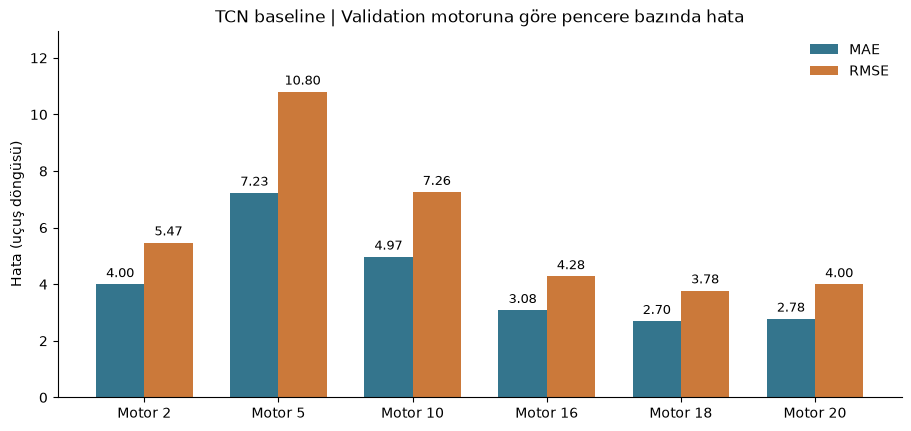

En yüksek iki MAE (döngü): Motor 5 (7.23), Motor 10 (4.97)
En yüksek iki RMSE (döngü): Motor 5 (10.80), Motor 10 (7.26)


In [18]:
import matplotlib.pyplot as plt
import numpy as np

comparison = results.sort_values("Validation motoru").reset_index(drop=True)
x = np.arange(len(comparison))
width = 0.36

fig, ax = plt.subplots(figsize=(9, 4.2), constrained_layout=True)

for offset, column, label, color in [
    (-width / 2, "MAE (döngü)", "MAE", "#34758D"),
    ( width / 2, "RMSE (döngü)", "RMSE", "#CB793A"),
]:
    bars = ax.bar(x + offset, comparison[column], width, label=label, color=color)
    ax.bar_label(bars, fmt="%.2f", padding=3, fontsize=9)

ax.set_xticks(x, [f"Motor {m}" for m in comparison["Validation motoru"]])
ax.set_ylabel("Hata (uçuş döngüsü)")
ax.set_title("TCN baseline | Validation motoruna göre pencere bazında hata")
ax.set_ylim(0, comparison["RMSE (döngü)"].max() * 1.2)
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

for column in ["MAE (döngü)", "RMSE (döngü)"]:
    highest = comparison.nlargest(2, column)
    ranking = ", ".join(
        f"Motor {int(row['Validation motoru'])} ({row[column]:.2f})"
        for _, row in highest.iterrows()
    )
    print(f"En yüksek iki {column}: {ranking}")

In [19]:
from pathlib import Path
from functools import lru_cache
import json
import matplotlib.pyplot as plt

import ipywidgets as widgets
import pandas as pd
from IPython.display import display


project = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "n_cmapss/outputs/tcn/window_256_stride_1024").is_dir())
runs_dir = project / "n_cmapss/outputs/tcn/window_256_stride_1024"
experiment_names = {
    "lr_0p0005": "Deney 1 — LR = 0.0005",
    "dropout_0p3_lr_0p001": "Deney 2 — Dropout = 0.3",
    "dropout_0p1_lr_0p001": "Deney 3 — Dropout = 0.1",
    "dropout_0p01_lr_0p001": "Deney 4 — Dropout = 0.01",
    "kernel_5_dropout_0p01_lr_0p001": "Deney 5 — Kernel size = 5",
    "blocks_6_kernel_3_dropout_0p01_lr_0p001": "Deney 6 — Temporal block = 6",
}
available = {p.name: p for p in runs_dir.iterdir()
             if p.is_dir() and any(p.glob("fold_*_*/metrics.csv"))}
experiments = {"Baseline (lr=0.001)": runs_dir}
for name in [*experiment_names, *sorted(available.keys() - experiment_names.keys())]:
    if name in available:
        experiments[experiment_names.get(name, name)] = available[name]
split_info = json.loads((project / "n_cmapss/processed/split_folds.json").read_text())
fold_units = {f["fold"]: f["validation_units"][0] for f in split_info["folds"]}

@lru_cache(maxsize=6)
def load_fold_for_plot(experiment, fold):
    # Sonuç tablosuyla aynı kural: metrikleri kaydedilmiş son çalışma.
    files = sorted(experiments[experiment].glob(f"fold_{fold}_*/metrics.csv"))
    if not files:
        raise FileNotFoundError(f"Fold {fold} için metrics.csv bulunamadı.")

    run_dir = files[-1].parent
    metric = pd.read_csv(run_dir / "metrics.csv").iloc[0]
    history = pd.read_csv(run_dir / "history.csv")
    predictions = pd.read_csv(run_dir / "predictions.csv")

    motor = int(metric["validation_unit"])
    if (
        int(metric["fold"]) != fold or motor != fold_units[fold]
        or set(predictions["unit"]) != {motor}
        or len(predictions) != int(metric["windows"])
    ):
        raise ValueError(f"Fold {fold}: motor veya pencere kayıtları uyuşmuyor.")

    by_flight = predictions.groupby("cycle", sort=True)
    if not by_flight["actual_rul"].nunique().eq(1).all():
        raise ValueError(f"Fold {fold}: aynı uçuşta birden fazla gerçek RUL var.")

    flights = by_flight.agg(
        actual=("actual_rul", "first"),
        predicted=("predicted_rul", "mean"),
        p10=("predicted_rul", lambda values: values.quantile(0.10)),
        p90=("predicted_rul", lambda values: values.quantile(0.90)),
    )
    return metric, history, flights


def plot_fold(experiment, fold):
    metric, history, flights = load_fold_for_plot(experiment, fold)
    motor = int(metric["validation_unit"])
    best_epoch = int(metric["best_epoch"])
    best = history.loc[history["epoch"] == best_epoch].iloc[0]

    fig, (loss_ax, rul_ax) = plt.subplots(
        1, 2, figsize=(13, 4.3), constrained_layout=True
    )

    # Sol: Her iki eğri de MSE, dolayısıyla aynı eksende karşılaştırılabilir.
    loss_ax.plot(history["epoch"], history["train_mse"],
                 color="#34758D", label="Training MSE")
    loss_ax.plot(history["epoch"], history["validation_mse"],
                 color="#CB793A", label="Validation MSE")
    loss_ax.axvline(best_epoch, color="#52616B", linestyle="--", linewidth=1)
    loss_ax.scatter(best_epoch, best["validation_mse"], color="#24735C",
                    zorder=3, label=f"En iyi epoch: {best_epoch}")
    loss_ax.set(title="Epoch boyunca kayıp", xlabel="Epoch",
                ylabel="MSE (uçuş döngüsü²)")
    loss_ax.legend(frameon=False)

    # Sağ: Her nokta bir uçuş. Bant aynı uçuştaki pencere tahminlerini özetler.
    cycles = flights.index.to_numpy()
    rul_ax.fill_between(
        cycles, flights["p10"].to_numpy(), flights["p90"].to_numpy(),
        color="#CB793A", alpha=0.22, label="Pencere tahminleri: %10–%90",
    )
    rul_ax.plot(cycles, flights["actual"], color="#263D50",
                linewidth=2, label="Gerçek RUL")
    rul_ax.plot(cycles, flights["predicted"], color="#CB793A",
                linewidth=2, label="Uçuş başına ortalama tahmin")
    rul_ax.set(title="Uçuş boyunca kalan ömür", xlabel="Uçuş numarası (cycle)",
               ylabel="RUL (uçuş döngüsü)")
    rul_ax.legend(frameon=False, fontsize=9)

    for ax in (loss_ax, rul_ax):
        ax.grid(axis="y", alpha=0.2)
        ax.spines[["top", "right"]].set_visible(False)

    fig.suptitle(
        f"{experiment} · Fold {fold} · Validation motoru {motor} · "
        f"Pencere MAE {metric['mae']:.2f} · RMSE {metric['rmse']:.2f}"
    )
    plt.show()


experiment_selector = widgets.Dropdown(options=list(experiments), value=next(iter(experiments)), description="Deney:")
selector = widgets.Dropdown(
    options=[(f"Fold {fold} — Motor {unit}", fold) for fold, unit in sorted(fold_units.items())],
    description="Fold:",
)
display(widgets.HBox([experiment_selector, selector]), widgets.interactive_output(
    plot_fold, {"experiment": experiment_selector, "fold": selector}
))

Output()

In [20]:
import pandas as pd

LOW_RUL_THRESHOLD = 20
satirlar = []

# splits ve runs_dir, altı fold sonuç tablosunu oluşturan hücreden geliyor.
for split in sorted(splits["folds"], key=lambda s: s["fold"]):
    fold = split["fold"]
    motor = split["validation_units"][0]

    # Önceki sonuç tablosuyla aynı eğitim kaydını kullan.
    dosyalar = sorted(runs_dir.glob(f"fold_{fold}_*/metrics.csv"))
    if not dosyalar:
        raise FileNotFoundError(f"Fold {fold} için metrics.csv bulunamadı.")

    pred = pd.read_csv(dosyalar[-1].with_name("predictions.csv"))
    if pred.empty or not pred["unit"].eq(motor).all():
        raise ValueError(f"Fold {fold} için Motor {motor} tahminlerini kontrol et.")

    dusuk_rul = pred.loc[pred["actual_rul"] <= LOW_RUL_THRESHOLD]

    for donem, veri in [
        ("Tüm ömür", pred),
        ("Gerçek RUL ≤ 20", dusuk_rul),
    ]:
        hata = veri["predicted_rul"] - veri["actual_rul"]

        satirlar.append({
            "Fold": fold,
            "Motor": motor,
            "Dönem": donem,
            "Uçuş sayısı": veri["cycle"].nunique(),
            "Pencere sayısı": len(veri),
            "MAE (döngü)": hata.abs().mean(),
            "RMSE (döngü)": hata.pow(2).mean() ** 0.5,
        })

rul_sonuclari = pd.DataFrame(satirlar)
display(rul_sonuclari.round(2).style.hide(axis="index"))

# Her motorun metriğine eşit ağırlık ver.
ortalama = (
    rul_sonuclari.groupby("Dönem", sort=False)[["MAE (döngü)", "RMSE (döngü)"]]
    .mean()
    .round(2)
)
print("Motorların eşit ağırlıklı ortalaması")
display(ortalama)

Fold,Motor,Dönem,Uçuş sayısı,Pencere sayısı,MAE (döngü),RMSE (döngü)
1,2,Tüm ömür,75,854,4.000000,5.470000
1,2,Gerçek RUL ≤ 20,21,227,1.650000,1.840000
2,5,Tüm ömür,89,1034,7.230000,10.800000
2,5,Gerçek RUL ≤ 20,21,241,1.610000,2.000000
3,10,Tüm ömür,82,955,4.970000,7.260000
3,10,Gerçek RUL ≤ 20,21,229,1.370000,1.720000
4,16,Tüm ömür,63,768,3.080000,4.280000
4,16,Gerçek RUL ≤ 20,21,246,1.810000,1.990000
5,18,Tüm ömür,71,890,2.700000,3.780000
5,18,Gerçek RUL ≤ 20,21,271,1.370000,1.810000


Motorların eşit ağırlıklı ortalaması


,MAE (döngü),RMSE (döngü)
Dönem,,
Tüm ömür,4.13,5.93
Gerçek RUL ≤ 20,1.48,1.81


## Learning Rate = 0.0005 Deney Sonuçları

Her satır bir validation motorunun en iyi epoch sonucudur. MAE ve RMSE uçuş döngüsü cinsindendir. Son satır altı motorun eşit ağırlıklı ortalamasıdır. Her fold için zaman damgasına göre en son kaydedilmiş metrik dosyası kullanılır.

In [21]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display

base = next(p / "n_cmapss" for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "n_cmapss/outputs/tcn/window_256_stride_1024").is_dir())
experiment_dir = base / "outputs/tcn/window_256_stride_1024/lr_0p0005"
splits_lr = json.loads((base / "processed/split_folds.json").read_text())["folds"]
records_lr = []
for split in sorted(splits_lr, key=lambda f: f["fold"]):
    fold = split["fold"]
    files = sorted(experiment_dir.glob(f"fold_{fold}_*/metrics.csv"))
    if not files:
        raise FileNotFoundError(f"Fold {fold} için metrics.csv bulunamadı.")
    metric = pd.read_csv(files[-1])
    assert len(metric) == 1 and metric.fold.iloc[0] == fold
    assert [metric.validation_unit.iloc[0]] == split["validation_units"]
    records_lr.append(metric)

scores_lr = pd.concat(records_lr, ignore_index=True).rename(columns={"mae":"MAE", "rmse":"RMSE"})
scores_lr = scores_lr[["fold", "validation_unit", "best_epoch", "windows", "MAE", "RMSE"]]
assert set(scores_lr.fold) == set(range(1, 7)) and scores_lr.validation_unit.nunique() == 6
assert scores_lr[["MAE", "RMSE"]].notna().all().all()
average_lr = {"fold": "Ortalama", "validation_unit": "—", "best_epoch": "—", "windows": "—",
              **scores_lr[["MAE", "RMSE"]].mean().to_dict()}
report_lr = pd.concat([scores_lr, pd.DataFrame([average_lr])], ignore_index=True)
display(report_lr.style.hide(axis="index").format({"MAE": "{:.4f}", "RMSE": "{:.4f}"}))

fold,validation_unit,best_epoch,windows,MAE,RMSE
1,2,20,854,4.5607,6.9554
2,5,48,1034,6.0517,9.4440
3,10,11,955,6.3935,9.3096
4,16,35,768,3.0110,4.3509
5,18,48,890,2.5371,3.7278
6,20,20,769,3.0083,4.2845
Ortalama,—,—,—,4.2604,6.3454


## Deney 2 — Dropout = 0.3 (LR = 0.001)

Her satır, ilgili fold için checkpoint ayarları doğrulanan en son tamamlanmış çalışmayı gösterir. MAE ve RMSE uçuş döngüsü cinsindendir. Son satırda her motor eşit ağırlıktadır.

In [22]:
from pathlib import Path
import json
import math
import pandas as pd
import torch
from IPython.display import display

def dropout_experiment_results():
    base = next(p / "n_cmapss" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "n_cmapss/processed/split_folds.json").is_file())
    folder = base / "outputs/tcn/window_256_stride_1024/dropout_0p3_lr_0p001"
    splits = json.loads((base / "processed/split_folds.json").read_text())["folds"]
    rows = []
    for split in sorted(splits, key=lambda s: s["fold"]):
        fold = split["fold"]
        for path in sorted(folder.glob(f"fold_{fold}_*/metrics.csv"), reverse=True):
            checkpoint_file = path.with_name("best_model.pt")
            if not checkpoint_file.is_file():
                continue
            ckpt = torch.load(checkpoint_file, map_location="cpu", weights_only=True)
            if not (ckpt["fold"] == fold
                    and math.isclose(ckpt["model_config"]["dropout"], 0.3)
                    and math.isclose(ckpt["learning_rate"], 0.001)):
                continue

            metric, = pd.read_csv(path).to_dict("records")
            if (metric["fold"] != fold
                    or [metric["validation_unit"]] != split["validation_units"]
                    or metric["best_epoch"] != ckpt["epoch"]
                    or metric["windows"] <= 0
                    or not all(math.isfinite(metric[k]) and metric[k] >= 0 for k in ("mae", "rmse"))
                    or not math.isclose(metric["rmse"], ckpt["validation_rmse"], rel_tol=1e-5)):
                raise ValueError(f"Checkpoint ve metrikler uyuşmuyor: {path}")
            rows.append(metric)
            break
        else:
            raise ValueError(f"Fold {fold}: istenen ayarlarla tamamlanmış deney bulunamadı.")

    table = pd.DataFrame(rows).rename(columns={"mae": "MAE", "rmse": "RMSE"})
    if sorted(table.fold) != list(range(1, 7)) or table.validation_unit.nunique() != 6:
        raise ValueError("Altı ayrı fold ve validation motoru bekleniyor.")
    table = table[["fold", "validation_unit", "best_epoch", "windows", "MAE", "RMSE"]]
    mean_row = dict(fold="Ortalama", validation_unit="—", best_epoch="—", windows="—",
                    **table[["MAE", "RMSE"]].mean().to_dict())
    return pd.concat([table, pd.DataFrame([mean_row])], ignore_index=True)

dropout_results = dropout_experiment_results()
display(dropout_results.style.hide(axis="index").format({"MAE": "{:.4f}", "RMSE": "{:.4f}"}))

fold,validation_unit,best_epoch,windows,MAE,RMSE
1,2,20,854,3.9045,5.6053
2,5,26,1034,7.6412,10.7726
3,10,40,955,4.6567,6.3858
4,16,42,768,3.3323,4.4842
5,18,38,890,2.7570,4.0248
6,20,9,769,4.1450,5.4985
Ortalama,—,—,—,4.4061,6.1285


## Deney 3 - Dropout = 0.1

Öğrenme oranı 0.001. Her satır, ilgili fold için checkpoint ayarları doğrulanan en son tamamlanmış çalışmayı gösterir. MAE ve RMSE uçuş döngüsü cinsindendir. Son satırda her motor eşit ağırlıktadır.

In [23]:
from pathlib import Path
import json
import math
import pandas as pd
import torch
from IPython.display import display

def experiment_3_results():
    base = next(p / "n_cmapss" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "n_cmapss/processed/split_folds.json").is_file())
    folder = base / "outputs/tcn/window_256_stride_1024/dropout_0p1_lr_0p001"
    splits = json.loads((base / "processed/split_folds.json").read_text())["folds"]
    rows = []
    for split in sorted(splits, key=lambda s: s["fold"]):
        fold = split["fold"]
        for path in sorted(folder.glob(f"fold_{fold}_*/metrics.csv"), reverse=True):
            checkpoint_file = path.with_name("best_model.pt")
            if not checkpoint_file.is_file():
                continue
            ckpt = torch.load(checkpoint_file, map_location="cpu", weights_only=True)
            if not (ckpt["fold"] == fold
                    and math.isclose(ckpt["model_config"]["dropout"], 0.1)
                    and math.isclose(ckpt["learning_rate"], 0.001)):
                continue

            metric, = pd.read_csv(path).to_dict("records")
            if (metric["fold"] != fold
                    or [metric["validation_unit"]] != split["validation_units"]
                    or metric["best_epoch"] != ckpt["epoch"]
                    or metric["windows"] <= 0
                    or not all(math.isfinite(metric[k]) and metric[k] >= 0 for k in ("mae", "rmse"))
                    or not math.isclose(metric["rmse"], ckpt["validation_rmse"], rel_tol=1e-5)):
                raise ValueError(f"Checkpoint ve metrikler uyuşmuyor: {path}")
            rows.append(metric)
            break
        else:
            raise ValueError(f"Fold {fold}: istenen ayarlarla tamamlanmış deney bulunamadı.")

    table = pd.DataFrame(rows).rename(columns={"mae": "MAE", "rmse": "RMSE"})
    if sorted(table.fold) != list(range(1, 7)) or table.validation_unit.nunique() != 6:
        raise ValueError("Altı ayrı fold ve validation motoru bekleniyor.")
    table = table[["fold", "validation_unit", "best_epoch", "windows", "MAE", "RMSE"]]
    mean_row = dict(fold="Ortalama", validation_unit="—", best_epoch="—", windows="—",
                    **table[["MAE", "RMSE"]].mean().to_dict())
    return pd.concat([table, pd.DataFrame([mean_row])], ignore_index=True)

dropout_01_results = experiment_3_results()
display(dropout_01_results.style.hide(axis="index").format({"MAE": "{:.4f}", "RMSE": "{:.4f}"}))

fold,validation_unit,best_epoch,windows,MAE,RMSE
1,2,20,854,3.6834,5.1866
2,5,27,1034,4.7458,7.1779
3,10,23,955,4.3145,6.2621
4,16,19,768,3.3502,4.8010
5,18,73,890,2.3415,3.3232
6,20,11,769,3.2335,4.4168
Ortalama,—,—,—,3.6115,5.1946


## Deney 4 - Dropout = 0.01

Öğrenme oranı 0.001. Her satır, ilgili fold için checkpoint ayarları doğrulanan en son tamamlanmış çalışmayı gösterir. MAE ve RMSE uçuş döngüsü cinsindendir. Son satırda her motor eşit ağırlıktadır.

In [24]:
from pathlib import Path
import json
import math
import pandas as pd
import torch
from IPython.display import display

def experiment_4_results():
    base = next(p / "n_cmapss" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "n_cmapss/processed/split_folds.json").is_file())
    folder = base / "outputs/tcn/window_256_stride_1024/dropout_0p01_lr_0p001"
    splits = json.loads((base / "processed/split_folds.json").read_text())["folds"]
    rows = []
    for split in sorted(splits, key=lambda s: s["fold"]):
        fold = split["fold"]
        for path in sorted(folder.glob(f"fold_{fold}_*/metrics.csv"), reverse=True):
            checkpoint_file = path.with_name("best_model.pt")
            if not checkpoint_file.is_file():
                continue
            ckpt = torch.load(checkpoint_file, map_location="cpu", weights_only=True)
            if not (ckpt["fold"] == fold
                    and math.isclose(ckpt["model_config"]["dropout"], 0.01)
                    and math.isclose(ckpt["learning_rate"], 0.001)):
                continue

            metric, = pd.read_csv(path).to_dict("records")
            if (metric["fold"] != fold
                    or [metric["validation_unit"]] != split["validation_units"]
                    or metric["best_epoch"] != ckpt["epoch"]
                    or metric["windows"] <= 0
                    or not all(math.isfinite(metric[k]) and metric[k] >= 0 for k in ("mae", "rmse"))
                    or not math.isclose(metric["rmse"], ckpt["validation_rmse"], rel_tol=1e-5)):
                raise ValueError(f"Checkpoint ve metrikler uyuşmuyor: {path}")
            rows.append(metric)
            break
        else:
            raise ValueError(f"Fold {fold}: istenen ayarlarla tamamlanmış deney bulunamadı.")

    table = pd.DataFrame(rows).rename(columns={"mae": "MAE", "rmse": "RMSE"})
    if sorted(table.fold) != list(range(1, 7)) or table.validation_unit.nunique() != 6:
        raise ValueError("Altı ayrı fold ve validation motoru bekleniyor.")
    table = table[["fold", "validation_unit", "best_epoch", "windows", "MAE", "RMSE"]]
    mean_row = dict(fold="Ortalama", validation_unit="—", best_epoch="—", windows="—",
                    **table[["MAE", "RMSE"]].mean().to_dict())
    return pd.concat([table, pd.DataFrame([mean_row])], ignore_index=True)

dropout_001_results = experiment_4_results()
display(dropout_001_results.style.hide(axis="index").format({"MAE": "{:.4f}", "RMSE": "{:.4f}"}))

fold,validation_unit,best_epoch,windows,MAE,RMSE
1,2,34,854,3.6953,5.3826
2,5,27,1034,4.6733,6.7938
3,10,35,955,3.8876,5.5116
4,16,8,768,3.9458,5.1804
5,18,43,890,2.2903,3.4915
6,20,28,769,2.9526,4.3451
Ortalama,—,—,—,3.5742,5.1175


## Deney 5 - kernel size = 5

Dropout 0.01, öğrenme oranı 0.001. Her motor için ayarları doğrulanan en son tamamlanmış fold kaydı gösterilir. Çizgi, sonucun henüz bulunmadığını belirtir. Altı sonuç tamamlandığında son satırda motorların eşit ağırlıklı ortalaması gösterilir.

In [25]:
from pathlib import Path
import json
import math
import pandas as pd
import torch
from IPython.display import display

def experiment_5_results():
    base = next(p / "n_cmapss" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "n_cmapss/processed/split_folds.json").is_file())
    folder = base / "outputs/tcn/window_256_stride_1024/kernel_5_dropout_0p01_lr_0p001"
    splits = json.loads((base / "processed/split_folds.json").read_text())["folds"]
    rows = []
    for split in sorted(splits, key=lambda s: s["fold"]):
        fold = split["fold"]
        for path in sorted(folder.rglob(f"fold_{fold}_*/metrics.csv"), key=lambda p: p.parent.name, reverse=True):
            checkpoint_file = path.with_name("best_model.pt")
            if not checkpoint_file.is_file():
                continue
            ckpt = torch.load(checkpoint_file, map_location="cpu", weights_only=True)
            if not (ckpt["fold"] == fold
                    and ckpt["model_config"]["kernel_size"] == 5
                    and math.isclose(ckpt["model_config"]["dropout"], 0.01)
                    and math.isclose(ckpt["learning_rate"], 0.001)):
                continue

            metric, = pd.read_csv(path).to_dict("records")
            if (metric["fold"] != fold
                    or [metric["validation_unit"]] != split["validation_units"]
                    or metric["best_epoch"] != ckpt["epoch"]
                    or metric["windows"] <= 0
                    or not all(math.isfinite(metric[k]) and metric[k] >= 0 for k in ("mae", "rmse"))
                    or not math.isclose(metric["rmse"], ckpt["validation_rmse"], rel_tol=1e-5)):
                raise ValueError(f"Checkpoint ve metrikler uyuşmuyor: {path}")
            rows.append(metric)
            break
        else:
            rows.append(dict(fold=fold, validation_unit=split["validation_units"][0],
                             best_epoch=None, windows=None, mae=None, rmse=None))

    table = pd.DataFrame(rows).rename(columns={"mae": "MAE", "rmse": "RMSE"})
    if sorted(table.fold) != list(range(1, 7)) or table.validation_unit.nunique() != 6:
        raise ValueError("Altı ayrı fold ve validation motoru bekleniyor.")
    table = table[["fold", "validation_unit", "best_epoch", "windows", "MAE", "RMSE"]]
    if table["MAE"].isna().any():
        return table
    mean_row = dict(fold="Ortalama", validation_unit="—", best_epoch="—", windows="—",
                    **table[["MAE", "RMSE"]].mean().to_dict())
    return pd.concat([table, pd.DataFrame([mean_row])], ignore_index=True)

kernel_5_results = experiment_5_results()
display(kernel_5_results.style.hide(axis="index").format({"MAE": "{:.4f}", "RMSE": "{:.4f}", "best_epoch": lambda v: str(int(v)) if v != "—" else v, "windows": lambda v: str(int(v)) if v != "—" else v}, na_rep="—"))

fold,validation_unit,best_epoch,windows,MAE,RMSE
1,2,48,854,3.6207,5.1255
2,5,27,1034,4.7424,6.8204
3,10,37,955,3.6395,5.6452
4,16,54,768,3.4048,4.6326
5,18,38,890,2.5960,3.7876
6,20,28,769,4.1594,5.6227
Ortalama,—,—,—,3.6938,5.2723


## Deney 6 - temporal block = 6

Altı temporal bloğun çıkış kanalları sırasıyla 32, 32, 64, 64, 64 ve 64’tür. Kernel boyutu 3, dropout 0.01 ve öğrenme oranı 0.001 olarak ayarlanmıştır. Her satır bir validation motorunun en iyi epoch sonucunu gösterir. Son satırdaki MAE ve RMSE, altı motorun eşit ağırlıklı ortalamasıdır ve uçuş döngüsü cinsindendir.

In [26]:
from pathlib import Path
import json
import math
import pandas as pd
import torch
from IPython.display import display

def experiment_6_results():
    base = next(p / "n_cmapss" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "n_cmapss/processed/split_folds.json").is_file())
    folder = base / "outputs/tcn/window_256_stride_1024/blocks_6_kernel_3_dropout_0p01_lr_0p001"
    splits = json.loads((base / "processed/split_folds.json").read_text())["folds"]
    rows = []
    for split in sorted(splits, key=lambda s: s["fold"]):
        fold = split["fold"]
        for path in sorted(folder.rglob(f"fold_{fold}_*/metrics.csv"), key=lambda p: p.parent.name, reverse=True):
            checkpoint_file = path.with_name("best_model.pt")
            if not checkpoint_file.is_file():
                continue
            ckpt = torch.load(checkpoint_file, map_location="cpu", weights_only=True)
            if not (ckpt["fold"] == fold
                    and tuple(ckpt["model_config"]["channels"]) == (32, 32, 64, 64, 64, 64)
                    and ckpt["model_config"]["kernel_size"] == 3
                    and math.isclose(ckpt["model_config"]["dropout"], 0.01)
                    and math.isclose(ckpt["learning_rate"], 0.001)):
                continue

            metric, = pd.read_csv(path).to_dict("records")
            if (metric["fold"] != fold
                    or [metric["validation_unit"]] != split["validation_units"]
                    or metric["best_epoch"] != ckpt["epoch"]
                    or metric["windows"] <= 0
                    or not all(math.isfinite(metric[k]) and metric[k] >= 0 for k in ("mae", "rmse"))
                    or not math.isclose(metric["rmse"], ckpt["validation_rmse"], rel_tol=1e-5)):
                raise ValueError(f"Checkpoint ve metrikler uyuşmuyor: {path}")
            rows.append(metric)
            break
        else:
            rows.append(dict(fold=fold, validation_unit=split["validation_units"][0],
                             best_epoch=None, windows=None, mae=None, rmse=None))

    table = pd.DataFrame(rows).rename(columns={"mae": "MAE", "rmse": "RMSE"})
    if sorted(table.fold) != list(range(1, 7)) or table.validation_unit.nunique() != 6:
        raise ValueError("Altı ayrı fold ve validation motoru bekleniyor.")
    table = table[["fold", "validation_unit", "best_epoch", "windows", "MAE", "RMSE"]]
    if table["MAE"].isna().any():
        return table
    mean_row = dict(fold="Ortalama", validation_unit="—", best_epoch="—", windows="—",
                    **table[["MAE", "RMSE"]].mean().to_dict())
    return pd.concat([table, pd.DataFrame([mean_row])], ignore_index=True)

blocks_6_results = experiment_6_results()
display(blocks_6_results.style.hide(axis="index").format({"MAE": "{:.4f}", "RMSE": "{:.4f}", "best_epoch": lambda v: str(int(v)) if v != "—" else v, "windows": lambda v: str(int(v)) if v != "—" else v}, na_rep="—"))

fold,validation_unit,best_epoch,windows,MAE,RMSE
1,2,40,854,3.3650,4.9976
2,5,40,1034,5.4817,7.9161
3,10,38,955,3.7962,5.5538
4,16,18,768,3.6319,5.1849
5,18,57,890,2.6231,3.5400
6,20,26,769,3.6813,5.2111
Ortalama,—,—,—,3.7632,5.4006


## Deney 7 - temporal block = 7 (32,32,32,32,32,32,32)

Her blok 32 çıkış kanalı kullanır. Kernel boyutu 3, dropout 0.01 ve öğrenme oranı 0.001’dir. Her satır bir validation motorunun en iyi epoch sonucunu gösterir. Son satırda motorların eşit ağırlıklı ortalama MAE ve RMSE değerleri uçuş döngüsü cinsinden verilmiştir.

In [27]:
from pathlib import Path
import json
import math
import pandas as pd
import torch
from IPython.display import display

def experiment_7_results():
    base = next(p / "n_cmapss" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "n_cmapss/processed/split_folds.json").is_file())
    folder = base / "outputs/tcn/window_256_stride_1024/blocks_7_32_kernel_3_dropout_0p01_lr_0p001"
    splits = json.loads((base / "processed/split_folds.json").read_text())["folds"]
    rows = []
    for split in sorted(splits, key=lambda s: s["fold"]):
        fold = split["fold"]
        for path in sorted(folder.rglob(f"fold_{fold}_*/metrics.csv"), key=lambda p: p.parent.name, reverse=True):
            checkpoint_file = path.with_name("best_model.pt")
            if not checkpoint_file.is_file():
                continue
            ckpt = torch.load(checkpoint_file, map_location="cpu", weights_only=True)
            if not (ckpt["fold"] == fold
                    and tuple(ckpt["model_config"]["channels"]) == (32,) * 7
                    and ckpt["model_config"]["kernel_size"] == 3
                    and math.isclose(ckpt["model_config"]["dropout"], 0.01)
                    and math.isclose(ckpt["learning_rate"], 0.001)):
                continue

            metric, = pd.read_csv(path).to_dict("records")
            if (metric["fold"] != fold
                    or [metric["validation_unit"]] != split["validation_units"]
                    or metric["best_epoch"] != ckpt["epoch"]
                    or metric["windows"] <= 0
                    or not all(math.isfinite(metric[k]) and metric[k] >= 0 for k in ("mae", "rmse"))
                    or not math.isclose(metric["rmse"], ckpt["validation_rmse"], rel_tol=1e-5)):
                raise ValueError(f"Checkpoint ve metrikler uyuşmuyor: {path}")
            rows.append(metric)
            break
        else:
            rows.append(dict(fold=fold, validation_unit=split["validation_units"][0],
                             best_epoch=None, windows=None, mae=None, rmse=None))

    table = pd.DataFrame(rows).rename(columns={"mae": "MAE", "rmse": "RMSE"})
    if sorted(table.fold) != list(range(1, 7)) or table.validation_unit.nunique() != 6:
        raise ValueError("Altı ayrı fold ve validation motoru bekleniyor.")
    table = table[["fold", "validation_unit", "best_epoch", "windows", "MAE", "RMSE"]]
    if table["MAE"].isna().any():
        return table
    mean_row = dict(fold="Ortalama", validation_unit="—", best_epoch="—", windows="—",
                    **table[["MAE", "RMSE"]].mean().to_dict())
    return pd.concat([table, pd.DataFrame([mean_row])], ignore_index=True)

blocks_7_32_results = experiment_7_results()
display(blocks_7_32_results.style.hide(axis="index").format({"MAE": "{:.4f}", "RMSE": "{:.4f}", "best_epoch": lambda v: str(int(v)) if v != "—" else v, "windows": lambda v: str(int(v)) if v != "—" else v}, na_rep="—"))

fold,validation_unit,best_epoch,windows,MAE,RMSE
1,2,57,854,3.2431,5.1185
2,5,15,1034,4.8591,7.1176
3,10,11,955,4.3045,6.0045
4,16,28,768,3.1391,4.6559
5,18,15,890,3.0681,4.1678
6,20,7,769,5.2061,6.7178
Ortalama,—,—,—,3.9700,5.6303


## Deney 8 - seed= 123

Checkpoint kayıtlarına göre seed 123, kanal dizilimi (32, 32, 64, 64, 64, 64, 64), kernel boyutu 3, dropout 0.01 ve öğrenme oranı 0.001. Her satır bir validation motorunun en iyi epoch sonucunu gösterir. Son satır altı motorun eşit ağırlıklı MAE ve RMSE ortalamasını uçuş döngüsü cinsinden verir.

**Seed doğrulama notu:** Checkpoint etiketi 123 olsa da mevcut eğitim betiğinde PyTorch ve veri yükleyicisi seed değerleri 42. Altı fold’un kayıtlı tahminleri Deney 4 ile birebir aynı. Bu tablo seed değişikliğinin etkisini ölçmek için kullanılamaz.

In [28]:
from pathlib import Path
import json
import math
import pandas as pd
import torch
from IPython.display import display

def experiment_8_results():
    base = next(p / "n_cmapss" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "n_cmapss/processed/split_folds.json").is_file())
    folder = base / "outputs/tcn/window_256_stride_1024/seed_123_blocks_7_kernel_3_dropout_0p01_lr_0p001"
    splits = json.loads((base / "processed/split_folds.json").read_text())["folds"]
    rows = []
    for split in sorted(splits, key=lambda s: s["fold"]):
        fold = split["fold"]
        for path in sorted(folder.rglob(f"fold_{fold}_*/metrics.csv"), key=lambda p: p.parent.name, reverse=True):
            checkpoint_file = path.with_name("best_model.pt")
            if not checkpoint_file.is_file():
                continue
            ckpt = torch.load(checkpoint_file, map_location="cpu", weights_only=True)
            if not (ckpt["fold"] == fold and ckpt["seed"] == 123
                    and tuple(ckpt["model_config"]["channels"]) == (32, 32, 64, 64, 64, 64, 64)
                    and ckpt["model_config"]["kernel_size"] == 3
                    and math.isclose(ckpt["model_config"]["dropout"], 0.01)
                    and math.isclose(ckpt["learning_rate"], 0.001)):
                continue

            metric, = pd.read_csv(path).to_dict("records")
            if (metric["fold"] != fold
                    or [metric["validation_unit"]] != split["validation_units"]
                    or metric["best_epoch"] != ckpt["epoch"]
                    or metric["windows"] <= 0
                    or not all(math.isfinite(metric[k]) and metric[k] >= 0 for k in ("mae", "rmse"))
                    or not math.isclose(metric["rmse"], ckpt["validation_rmse"], rel_tol=1e-5)):
                raise ValueError(f"Checkpoint ve metrikler uyuşmuyor: {path}")
            rows.append(metric)
            break
        else:
            rows.append(dict(fold=fold, validation_unit=split["validation_units"][0],
                             best_epoch=None, windows=None, mae=None, rmse=None))

    table = pd.DataFrame(rows).rename(columns={"mae": "MAE", "rmse": "RMSE"})
    if sorted(table.fold) != list(range(1, 7)) or table.validation_unit.nunique() != 6:
        raise ValueError("Altı ayrı fold ve validation motoru bekleniyor.")
    table = table[["fold", "validation_unit", "best_epoch", "windows", "MAE", "RMSE"]]
    if table["MAE"].isna().any():
        return table
    mean_row = dict(fold="Ortalama", validation_unit="—", best_epoch="—", windows="—",
                    **table[["MAE", "RMSE"]].mean().to_dict())
    return pd.concat([table, pd.DataFrame([mean_row])], ignore_index=True)

seed_123_results = experiment_8_results()
display(seed_123_results.style.hide(axis="index").format({"MAE": "{:.4f}", "RMSE": "{:.4f}", "best_epoch": lambda v: str(int(v)) if v != "—" else v, "windows": lambda v: str(int(v)) if v != "—" else v}, na_rep="—"))

fold,validation_unit,best_epoch,windows,MAE,RMSE
1,2,42,854,3.4617,4.9503
2,5,48,1034,4.3169,6.4805
3,10,13,955,4.5058,6.3197
4,16,44,768,3.0435,4.2945
5,18,30,890,2.6134,3.7087
6,20,32,769,2.8075,4.3246
Ortalama,—,—,—,3.4581,5.0130


## Deney 9 - seed= 2026

Her satır bir validation motorunun en iyi epoch sonucunu gösterir. Son satırda altı motorun eşit ağırlıklı MAE ve RMSE ortalamaları uçuş döngüsü cinsinden verilmiştir.

In [29]:
from pathlib import Path
import json
import math
import pandas as pd
import torch
from IPython.display import display

def experiment_9_results():
    base = next(p / "n_cmapss" for p in (Path.cwd(), *Path.cwd().parents)
                if (p / "n_cmapss/processed/split_folds.json").is_file())
    folder = base / "outputs/tcn/window_256_stride_1024/seed_2026_blocks_7_kernel_3_dropout_0p01_lr_0p001"
    splits = json.loads((base / "processed/split_folds.json").read_text())["folds"]
    rows = []
    for split in sorted(splits, key=lambda s: s["fold"]):
        fold = split["fold"]
        for path in sorted(folder.rglob(f"fold_{fold}_*/metrics.csv"), key=lambda p: p.parent.name, reverse=True):
            checkpoint_file = path.with_name("best_model.pt")
            if not checkpoint_file.is_file():
                continue
            ckpt = torch.load(checkpoint_file, map_location="cpu", weights_only=True)
            if not (ckpt["fold"] == fold and ckpt["seed"] == 2026
                    and tuple(ckpt["model_config"]["channels"]) == (32, 32, 64, 64, 64, 64, 64)
                    and ckpt["model_config"]["kernel_size"] == 3
                    and math.isclose(ckpt["model_config"]["dropout"], 0.01)
                    and math.isclose(ckpt["learning_rate"], 0.001)):
                continue

            metric, = pd.read_csv(path).to_dict("records")
            if (metric["fold"] != fold
                    or [metric["validation_unit"]] != split["validation_units"]
                    or metric["best_epoch"] != ckpt["epoch"]
                    or metric["windows"] <= 0
                    or not all(math.isfinite(metric[k]) and metric[k] >= 0 for k in ("mae", "rmse"))
                    or not math.isclose(metric["rmse"], ckpt["validation_rmse"], rel_tol=1e-5)):
                raise ValueError(f"Checkpoint ve metrikler uyuşmuyor: {path}")
            rows.append(metric)
            break
        else:
            rows.append(dict(fold=fold, validation_unit=split["validation_units"][0],
                             best_epoch=None, windows=None, mae=None, rmse=None))

    table = pd.DataFrame(rows).rename(columns={"mae": "MAE", "rmse": "RMSE"})
    if sorted(table.fold) != list(range(1, 7)) or table.validation_unit.nunique() != 6:
        raise ValueError("Altı ayrı fold ve validation motoru bekleniyor.")
    table = table[["fold", "validation_unit", "best_epoch", "windows", "MAE", "RMSE"]]
    if table["MAE"].isna().any():
        return table
    mean_row = dict(fold="Ortalama", validation_unit="—", best_epoch="—", windows="—",
                    **table[["MAE", "RMSE"]].mean().to_dict())
    return pd.concat([table, pd.DataFrame([mean_row])], ignore_index=True)

seed_2026_results = experiment_9_results()
display(seed_2026_results.style.hide(axis="index").format({"MAE": "{:.4f}", "RMSE": "{:.4f}", "best_epoch": lambda v: str(int(v)) if v != "—" else v, "windows": lambda v: str(int(v)) if v != "—" else v}, na_rep="—"))

fold,validation_unit,best_epoch,windows,MAE,RMSE
1,2,25,854,3.9320,5.5904
2,5,46,1034,4.4227,6.2585
3,10,17,955,4.0878,5.7391
4,16,20,768,3.5473,4.7115
5,18,32,890,2.6794,3.7626
6,20,10,769,4.0532,5.5504
Ortalama,—,—,—,3.7871,5.2688


## Deney özetleri

Her deney ve fold için en son tamamlanan kaydın validation tahminleri kullanılır. Önce her motorun pencere hatalarından MAE ve RMSE (ikisi de uçuş döngüsü cinsinden) hesaplanır, ardından her metrik altı motora eşit ağırlık verilerek ortalanır. Yeşil hücreler en düşük değerleri gösterir. Seed checkpoint etiketidir. Eski checkpoint’lerde LR alanı bulunmadığında deneyin belgelenmiş öğrenme oranı kullanılır.

In [30]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import torch
from IPython.display import display

base = next(p / "n_cmapss" for p in (Path.cwd(), *Path.cwd().parents)
            if (p / "n_cmapss/outputs/tcn/window_256_stride_1024").is_dir())
splits = json.loads((base / "processed/split_folds.json").read_text())["folds"]
experiments_summary = [
    ("Baseline", ".", 0.001),
    ("Deney 1", "lr_0p0005", 0.0005),
    ("Deney 2", "dropout_0p3_lr_0p001", 0.001),
    ("Deney 3", "dropout_0p1_lr_0p001", 0.001),
    ("Deney 4", "dropout_0p01_lr_0p001", 0.001),
    ("Deney 5", "kernel_5_dropout_0p01_lr_0p001", 0.001),
    ("Deney 6", "blocks_6_kernel_3_dropout_0p01_lr_0p001", 0.001),
    ("Deney 7", "blocks_7_32_kernel_3_dropout_0p01_lr_0p001", 0.001),
    ("Deney 8", "seed_123_blocks_7_kernel_3_dropout_0p01_lr_0p001", 0.001),
    ("Deney 9", "seed_2026_blocks_7_kernel_3_dropout_0p01_lr_0p001", 0.001),
]

def summarize_run(label, folder, documented_lr):
    mae_values, rmse_values, settings = [], [], set()
    for split in splits:
        fold = split["fold"]
        files = sorted((base / "outputs/tcn/window_256_stride_1024" / folder).glob(f"fold_{fold}_*/metrics.csv"))
        run = files[-1].parent
        checkpoint = torch.load(run / "best_model.pt", map_location="cpu", weights_only=True)
        config = checkpoint["model_config"]
        settings.add((tuple(config["channels"]), config["kernel_size"], config["dropout"],
                      checkpoint.get("learning_rate", documented_lr), checkpoint["seed"]))
        predictions = pd.read_csv(run / "predictions.csv")
        metric, = pd.read_csv(run / "metrics.csv").to_dict("records")
        assert checkpoint["fold"] == metric["fold"] == fold
        assert set(predictions.unit) == set(split["validation_units"]) == {metric["validation_unit"]}
        assert len(predictions) == metric["windows"] and predictions.window_id.is_unique
        error = (predictions.predicted_rul - predictions.actual_rul).to_numpy()
        mae = np.abs(error).mean()
        rmse = np.sqrt(np.mean(error ** 2))
        assert np.isclose(mae, metric["mae"]) and np.isclose(rmse, metric["rmse"])
        mae_values.append(mae)
        rmse_values.append(rmse)
    assert len(mae_values) == 6 and len(settings) == 1
    (channels, kernel, dropout, lr, seed), = settings
    return {"Model": label, "LR": lr, "Dropout": dropout, "Kernel": kernel,
            "Blok": len(channels), "Blok kanalları": ", ".join(map(str, channels)),
            "Seed (kayıt)": seed, "Ort. MAE": np.mean(mae_values),
            "Ort. RMSE": np.mean(rmse_values)}

experiment_summary = pd.DataFrame(summarize_run(*entry) for entry in experiments_summary)
display(experiment_summary.style.hide(axis="index")
        .format({"LR": "{:.4f}", "Dropout": "{:.2f}", "Ort. MAE": "{:.4f}", "Ort. RMSE": "{:.4f}"})
        .highlight_min(subset=["Ort. MAE", "Ort. RMSE"], color="#dc4946"))

Model,LR,Dropout,Kernel,Blok,Blok kanalları,Seed (kayıt),Ort. MAE,Ort. RMSE
Baseline,0.0010,0.20,3,7,"32, 32, 64, 64, 64, 64, 64",42,4.1251,5.9301
Deney 1,0.0005,0.20,3,7,"32, 32, 64, 64, 64, 64, 64",42,4.2604,6.3454
Deney 2,0.0010,0.30,3,7,"32, 32, 64, 64, 64, 64, 64",42,4.4061,6.1285
Deney 3,0.0010,0.10,3,7,"32, 32, 64, 64, 64, 64, 64",42,3.6115,5.1946
Deney 4,0.0010,0.01,3,7,"32, 32, 64, 64, 64, 64, 64",42,3.5742,5.1175
Deney 5,0.0010,0.01,5,7,"32, 32, 64, 64, 64, 64, 64",42,3.6938,5.2723
Deney 6,0.0010,0.01,3,6,"32, 32, 64, 64, 64, 64",42,3.7632,5.4006
Deney 7,0.0010,0.01,3,7,"32, 32, 32, 32, 32, 32, 32",42,3.9700,5.6303
Deney 8,0.0010,0.01,3,7,"32, 32, 64, 64, 64, 64, 64",123,3.4581,5.0130
Deney 9,0.0010,0.01,3,7,"32, 32, 64, 64, 64, 64, 64",2026,3.7871,5.2688


**Çıkarım.** Baseline ile aynı mimari ve kayıtlı seed altında dropout’u 0,20’den 0,01’e düşürmek (Deney 4), ortalama RMSE’yi 5,9301’den 5,1175’e indirdi (yaklaşık %13,7). En düşük ort. mae Deney 8’de görüldü (3,4581 uçuş döngüsü). En düşük ort. rmse Deney 8’de görüldü (5,0130 uçuş döngüsü). Deney 8’in önceki bölümündeki seed uyarısı ilk koşuya aittir.

<a id="window-256-stride-256"></a>

# WINDOW 256 STRIDE 256

## Deney 1: Baseline Model

Kanallar `(32, 32, 64, 64, 64, 64, 64)`, kernel 3, dropout 0.01, Adam, öğrenme oranı 0.001, batch size 64, seed 42. Önceki seçilen hiperparametrelerle stride=256 verisi üzerinde sıfırdan eğitim.

Her satır bir validation motorunun en iyi epoch sonucudur. MAE ve RMSE uçuş döngüsü cinsindendir. Son satır altı motorun eşit ağırlıklı ortalamasıdır. Her fold için bu deney klasöründeki en son tamamlanmış kayıt seçilir; tahminler yeni pencere metadata’sıyla ve metrikler yeniden hesaplanan hatalarla doğrulanır.

In [31]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import torch
from IPython.display import display


def stride256_baseline_results():
    base = next(p / 'n_cmapss' for p in (Path.cwd(), *Path.cwd().parents)
                if (p / 'n_cmapss/processed/window_256_stride_256/split_folds.json').is_file())
    data_dir = base / 'processed/window_256_stride_256'
    folder = base / 'outputs/tcn/window_256_stride_256/seed_42_blocks_7_kernel_3_dropout_0p01_lr_0p001'
    splits = json.loads((data_dir / 'split_folds.json').read_text())['folds']
    metadata = pd.read_csv(data_dir / 'window_metadata.csv')
    rows = []
    for split in sorted(splits, key=lambda s: s['fold']):
        fold = split['fold']
        unit = split['validation_units'][0]
        files = [p for p in sorted(folder.glob(f'fold_{fold}_*/metrics.csv'))
                 if p.with_name('best_model.pt').is_file() and p.with_name('predictions.csv').is_file()]
        if not files:
            raise FileNotFoundError(f'Fold {fold}: tamamlanmış eğitim bulunamadı.')
        path = files[-1]
        metrics = pd.read_csv(path)
        assert len(metrics) == 1
        metric = metrics.iloc[0]
        ckpt = torch.load(path.with_name('best_model.pt'), map_location='cpu', weights_only=True)
        assert ckpt['window_size'] == 256 and ckpt['stride'] == 256
        assert ckpt['fold'] == fold and ckpt['seed'] == 42
        assert ckpt['model_config'] == dict(input_channels=18, channels=(32, 32, 64, 64, 64, 64, 64), kernel_size=3, dropout=0.01)
        assert np.isclose(ckpt['learning_rate'], 0.001)
        pred = pd.read_csv(path.with_name('predictions.csv')).sort_values('window_id')
        expected = metadata.loc[metadata.unit == unit].sort_values('window_id')
        assert len(pred) == len(expected) == int(metric['windows'])
        assert int(metric['fold']) == fold and int(metric['validation_unit']) == unit
        assert int(metric['best_epoch']) == ckpt['epoch']
        for column in ['window_id', 'unit', 'cycle']:
            np.testing.assert_array_equal(pred[column].to_numpy(), expected[column].to_numpy())
        np.testing.assert_array_equal(pred.actual_rul.to_numpy(), expected.rul.to_numpy())
        error = pred.predicted_rul.to_numpy() - pred.actual_rul.to_numpy()
        assert np.isfinite(error).all()
        mae, rmse = np.abs(error).mean(), np.sqrt(np.mean(error ** 2))
        np.testing.assert_allclose([mae, rmse], [metric['mae'], metric['rmse']], rtol=1e-10)
        rows.append({'Fold': fold, 'Validation motoru': unit,
                     'En iyi epoch': int(metric['best_epoch']), 'Pencere sayısı': len(pred),
                     'MAE (döngü)': mae, 'RMSE (döngü)': rmse})
    result = pd.DataFrame(rows)
    average = {'Fold': 'Ortalama (motorlar eşit ağırlıklı)', 'Validation motoru': '—',
               'En iyi epoch': '—', 'Pencere sayısı': '—',
               'MAE (döngü)': result['MAE (döngü)'].mean(),
               'RMSE (döngü)': result['RMSE (döngü)'].mean()}
    return pd.concat([result, pd.DataFrame([average])], ignore_index=True)


stride256_baseline_table = stride256_baseline_results()
display(stride256_baseline_table.style.hide(axis='index').format({
    'MAE (döngü)': '{:.4f}', 'RMSE (döngü)': '{:.4f}',
}))


Fold,Validation motoru,En iyi epoch,Pencere sayısı,MAE (döngü),RMSE (döngü)
1,2,14,3294,3.5354,5.1541
2,5,9,3990,4.8644,7.0372
3,10,24,3685,3.2252,4.8147
4,16,11,2955,3.1169,4.3694
5,18,30,3446,2.3224,3.4305
6,20,18,2969,3.5526,5.2053
Ortalama (motorlar eşit ağırlıklı),—,—,—,3.4362,5.0019


## Deney 2: Learning Rate = 0.0005

**Window 256 · Stride 256.** Kanallar `(32, 32, 64, 64, 64, 64, 64)`, kernel 3, dropout 0.01, Adam, seed 42. Sonuçlar `outputs/tcn/window_256_stride_256/lr_0p0005/` klasöründen okunur.

Her satır ilgili validation motorunun en iyi epoch sonucunu gösterir. MAE ve RMSE uçuş döngüsü cinsindendir. Son satır altı motorun eşit ağırlıklı metrik ortalamasıdır. Her fold için en son tamamlanmış kayıt seçilir; checkpoint ayarları, pencere kimlikleri, RUL etiketleri ve tahminlerden yeniden hesaplanan metrikler doğrulanır.

In [32]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import torch
from IPython.display import display


def stride256_lr0005_results():
    base = next(p / 'n_cmapss' for p in (Path.cwd(), *Path.cwd().parents)
                if (p / 'n_cmapss/processed/window_256_stride_256/split_folds.json').is_file())
    data_dir = base / 'processed/window_256_stride_256'
    folder = base / 'outputs/tcn/window_256_stride_256/lr_0p0005'
    splits = json.loads((data_dir / 'split_folds.json').read_text())['folds']
    metadata = pd.read_csv(data_dir / 'window_metadata.csv')
    rows = []
    for split in sorted(splits, key=lambda s: s['fold']):
        fold = split['fold']
        unit = split['validation_units'][0]
        files = [p for p in sorted(folder.glob(f'fold_{fold}_*/metrics.csv'))
                 if p.with_name('best_model.pt').is_file() and p.with_name('predictions.csv').is_file()]
        if not files:
            raise FileNotFoundError(f'Fold {fold}: tamamlanmış eğitim bulunamadı.')
        path = files[-1]
        metrics = pd.read_csv(path)
        assert len(metrics) == 1
        metric = metrics.iloc[0]
        ckpt = torch.load(path.with_name('best_model.pt'), map_location='cpu', weights_only=True)
        assert ckpt['window_size'] == 256 and ckpt['stride'] == 256
        assert ckpt['fold'] == fold and ckpt['seed'] == 42
        assert ckpt['model_config'] == dict(input_channels=18, channels=(32, 32, 64, 64, 64, 64, 64), kernel_size=3, dropout=0.01)
        assert np.isclose(ckpt['learning_rate'], 0.0005)
        pred = pd.read_csv(path.with_name('predictions.csv')).sort_values('window_id')
        expected = metadata.loc[metadata.unit == unit].sort_values('window_id')
        assert len(pred) == len(expected) == int(metric['windows'])
        assert int(metric['fold']) == fold and int(metric['validation_unit']) == unit
        assert int(metric['best_epoch']) == ckpt['epoch']
        for column in ['window_id', 'unit', 'cycle']:
            np.testing.assert_array_equal(pred[column].to_numpy(), expected[column].to_numpy())
        np.testing.assert_array_equal(pred.actual_rul.to_numpy(), expected.rul.to_numpy())
        error = pred.predicted_rul.to_numpy() - pred.actual_rul.to_numpy()
        assert np.isfinite(error).all()
        mae, rmse = np.abs(error).mean(), np.sqrt(np.mean(error ** 2))
        np.testing.assert_allclose([mae, rmse], [metric['mae'], metric['rmse']], rtol=1e-10)
        rows.append({'Fold': fold, 'Validation motoru': unit,
                     'En iyi epoch': int(metric['best_epoch']), 'Pencere sayısı': len(pred),
                     'MAE (döngü)': mae, 'RMSE (döngü)': rmse})
    result = pd.DataFrame(rows)
    average = {'Fold': 'Ortalama (motorlar eşit ağırlıklı)', 'Validation motoru': '—',
               'En iyi epoch': '—', 'Pencere sayısı': '—',
               'MAE (döngü)': result['MAE (döngü)'].mean(),
               'RMSE (döngü)': result['RMSE (döngü)'].mean()}
    return pd.concat([result, pd.DataFrame([average])], ignore_index=True)


stride256_lr0005_table = stride256_lr0005_results()
display(stride256_lr0005_table.style.hide(axis='index').format({
    'MAE (döngü)': '{:.4f}', 'RMSE (döngü)': '{:.4f}',
}))


Fold,Validation motoru,En iyi epoch,Pencere sayısı,MAE (döngü),RMSE (döngü)
1,2,28,3294,3.3555,4.9454
2,5,43,3990,4.2822,6.5890
3,10,25,3685,3.6531,5.2059
4,16,13,2955,3.2300,4.5540
5,18,14,3446,2.2382,3.2809
6,20,5,2969,4.2723,6.1064
Ortalama (motorlar eşit ağırlıklı),—,—,—,3.5052,5.1136
